# Experiment 4: Intrusive stochastic elasticity

Aluminum cube of side $L=10$ cm, clamped at its base and compressed by a uniform pressure
$p=10$ MPa on its top face. Its elastic modulus is a random field with mean $E_0=70$ GPa, a
standard deviation of 5% and a correlation length of 7.5 cm, represented by a truncated
Karhunen–Loève expansion with $M\leq10$ uniform random variables. A single solve returns the
random displacement field, from which the statistics follow without sampling
(Sec. 4.4 and Fig. 9 of the paper).

In [1]:
import warnings
from itertools import product
from time import perf_counter, process_time
from resource import getrusage, RUSAGE_SELF
from typing import Any

import numpy as np
import scipy.linalg as la
from matplotlib.axes import Axes
from matplotlib.lines import Line2D
from seemps.state import MPS, MPSSum, mps_tensor_product, simplify
from seemps.analysis.mesh import ChebyshevInterval, Mesh
from seemps_galerkin.mps.defaults import DEFAULT_SVD_STRATEGY
from seemps_galerkin.mps.factories import mps_identity, mps_zeros
from seemps_galerkin.mps.linear import AMEnSolver
from seemps_galerkin.solve import solve_mps_bvp, solve_dense_bvp
from seemps_galerkin.logger import Logger
from seemps_galerkin.problem import (
    TensorField,
    BulkProblem,
    BoundaryProblem,
    BoundaryFace,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
)
from seemps_galerkin.dense.factories import (
    op_gram,
    op_chebyshev_transform,
    op_chebyshev_derivative,
    op_chebyshev_recombination,
    op_weighted_gram,
)
from seemps_galerkin.typing import Vector, Tensor3
from tools.data import save_pkl, load_pkl, fresh_process
from tools.solver import SolverDiagnostics
from seemps_galerkin.mps.preconditioning import ParametricBasisSolver
from tools.plot import set_plot_styles, create_subplots

set_plot_styles()

E0 = 70e9  # Pa
P = 10e6  # Pa, uniform compressive pressure
L = W = H = 0.1  # m
ν_P = 0.3
σ = 0.05
ℓ = 1.5
λ_1 = ν_P / ((1.0 + ν_P) * (1.0 - 2.0 * ν_P))
λ_2 = 1.0 / (2.0 * (1.0 + ν_P))

N_SPATIAL = 8
NUM_SAMPLES = 100
VARIANCE_TARGET = 0.99
MIN_KL_MODES = 10
N_ξ_range = [2, 4, 8]
TOLERANCE = 1e-5
AUDIT_TOLERANCE = 5e-5
QTT_TOLERANCE = 1e-10
MAX_SWEEPS = 30
ENRICHMENT_RANK = 16
RESIDUAL_RANK = 16
MAX_RANK = 192
STRATEGY = DEFAULT_SVD_STRATEGY.replace(
    tolerance=QTT_TOLERANCE,
    simplification_tolerance=QTT_TOLERANCE,
    max_bond_dimension=1024,
    max_sweeps=4,
)
RESULTS_FILE = "data/4_results_mps.pkl"

## 1. Random material field

Karhunen–Loève modes of a Gaussian covariance with correlation length $\ell=1.5$ in reference
coordinates (7.5 cm). The truncations $M=1,\ldots,10$ are nested, and $M=10$ captures 99.3% of
the variance.

In [2]:
def get_kl_modes(
    mesh: Mesh, M: int, num_quad: int = 64, correlation_length=None
) -> tuple[Vector, Tensor3]:
    ell = ℓ if correlation_length is None else correlation_length
    # A 3D truncation may need more modes than the auxiliary 1D quadrature.
    if M < 1 or M > num_quad**3:
        raise ValueError("KL truncation must lie between 1 and num_quad**3")
    num_1d = min(M, num_quad)
    # Nyström discretization of the separable Gaussian covariance operator.

    # 1D KL eigendecomposition on an auxiliary quadrature grid
    x_quad, w = np.polynomial.legendre.leggauss(num_quad)
    K = np.exp(-((x_quad[:, None] - x_quad[None, :]) ** 2) / (2.0 * ell**2))
    sqrt_w = np.sqrt(w)

    λ_1d, Q = la.eigh(
        sqrt_w[:, None] * K * sqrt_w[None, :],
    )
    λ_1d = λ_1d[::-1][:num_1d]
    Q = Q[:, ::-1][:, :num_1d]
    # Fix the signs and ordering once so every truncation is a prefix.
    Q *= np.sign(Q[np.argmax(abs(Q), axis=0), np.arange(num_1d)])

    # Largest M tensor-product 3D eigenmodes
    indices = np.array(list(product(range(num_1d), repeat=3)))
    λ = np.prod(λ_1d[indices], axis=1)

    order = np.argsort(-np.round(λ / λ.max(), 14), kind="stable")[:M]
    indices = indices[order]
    λ = λ[order]

    # Evaluate only the 1D modes used by the selected 3D products.
    used = int(indices.max()) + 1
    λ_1d, Q = λ_1d[:used], Q[:, :used]
    if λ_1d[-1] <= 1e-14 * λ_1d[0]:
        raise ValueError("KL truncation exceeds the resolved Nystrom spectrum")

    # Evaluate 1D eigenfunctions directly on the spatial Chebyshev nodes
    φ_axes = []
    for interval in mesh.intervals[:3]:
        x = interval.to_vector()
        K_x = np.exp(-((x[:, None] - x_quad[None, :]) ** 2) / (2.0 * ell**2))
        φ_axes.append(K_x @ (sqrt_w[:, None] * Q) / λ_1d[None, :])

    φ = np.array([[φ_axes[0][:, i], φ_axes[1][:, j], φ_axes[2][:, k]] for i, j, k in indices])
    return λ, φ


def material_diagnostics(M, N=8):
    """Conservative uniform positivity bound for the spatial polynomial modulus."""

    mesh = Mesh([ChebyshevInterval(-1, 1, N, endpoints=False)] * 3)
    lam, phi = get_kl_modes(mesh, M)
    C = op_chebyshev_transform(N)
    # Exact maxima of each polynomial on each subinterval. Summing products
    # over common spatial boxes is sharper than summing global mode maxima.
    edges = np.linspace(-1, 1, 33)
    envelope = np.zeros((len(edges) - 1,) * 3)
    global_variation = 0.0
    for eigenvalue, mode in zip(lam, phi):
        axis_bounds = []
        for values in mode:
            coefficients = C @ values
            roots = np.polynomial.chebyshev.chebroots(np.polynomial.chebyshev.chebder(coefficients))
            real = roots[(abs(roots.imag) < 1e-10) & (abs(roots.real) <= 1)].real
            endpoint_values = abs(np.polynomial.chebyshev.chebval(edges, coefficients))
            bounds = np.maximum(endpoint_values[:-1], endpoint_values[1:])
            for x in real:
                index = min(len(bounds) - 1, int(np.searchsorted(edges, x, side="right") - 1))
                bounds[index] = max(
                    bounds[index], abs(np.polynomial.chebyshev.chebval(x, coefficients))
                )
            axis_bounds.append(bounds)
        amplitude = σ * np.sqrt(3 * eigenvalue)
        envelope += amplitude * np.einsum("i,j,k->ijk", *axis_bounds)
        global_variation += amplitude * np.prod([max(b) for b in axis_bounds])
    variation = float(envelope.max())
    return {
        "captured_KL_trace": float(np.sum(lam) / 8),
        "modulus_lower_bound": float(1 - variation),
        "modulus_upper_bound": float(1 + variation),
        "global_separated_lower_bound": float(1 - global_variation),
        "eigenvalues": lam,
    }


# Select the cutoff from the full resolved tensor-product covariance spectrum.
xq, wq = np.polynomial.legendre.leggauss(64)
K = np.exp(-((xq[:, None] - xq[None, :]) ** 2) / (2 * ℓ**2))
eigenvalues_1d = la.eigvalsh(np.sqrt(wq[:, None] * wq[None, :]) * K)[::-1]
eigenvalues_1d = eigenvalues_1d[eigenvalues_1d > 1e-14]
eigenvalues = np.sort(
    (
        eigenvalues_1d[:, None, None]
        * eigenvalues_1d[None, :, None]
        * eigenvalues_1d[None, None, :]
    ).ravel()
)[::-1]
cutoff = max(MIN_KL_MODES - 1, np.searchsorted(np.cumsum(eigenvalues) / 8, VARIANCE_TARGET))
M_max = int(np.count_nonzero(eigenvalues >= eigenvalues[cutoff] * (1 - 1e-10)))
M_range = list(range(1, M_max + 1))
material_by_mode = {}
for M in M_range:
    data = material_by_mode[M] = material_diagnostics(M, N_SPATIAL)
    print(
        f"M={M}: trace={data['captured_KL_trace']:.4%}, E/E0 >= {data['modulus_lower_bound']:.6f}"
    )
assert M_max >= MIN_KL_MODES
assert data["captured_KL_trace"] >= VARIANCE_TARGET
assert data["modulus_lower_bound"] > 0

M=1: trace=67.5192%, E/E0 >= 0.914530
M=2: trace=76.4068%, E/E0 >= 0.881417
M=3: trace=85.2943%, E/E0 >= 0.858642
M=4: trace=94.1819%, E/E0 >= 0.839789
M=5: trace=95.3518%, E/E0 >= 0.821336
M=6: trace=96.5217%, E/E0 >= 0.803876
M=7: trace=97.6915%, E/E0 >= 0.785177
M=8: trace=98.2272%, E/E0 >= 0.773892
M=9: trace=98.7628%, E/E0 >= 0.763007
M=10: trace=99.2984%, E/E0 >= 0.752838


## 2. Dense reference

Affine dense operator $A(\boldsymbol\xi)=A_0+\sum_r\xi_r A_r$, used to solve independent
realizations for the error check.

In [3]:
def dense_affine(M, N=8):
    """Independent dense assembly using the KL modes' exact separated Gram factors."""

    t = perf_counter()
    mesh = Mesh([ChebyshevInterval(-1, 1, N, endpoints=False)] * 3)
    eigenvalues, phi = get_kl_modes(mesh, M)
    C = op_chebyshev_transform(N)
    D = op_chebyshev_derivative(N)
    Zaxis = [np.eye(N), np.eye(N), op_chebyshev_recombination(N, True, False)[:, :-1]]
    Z = np.kron(np.eye(3), np.kron(Zaxis[0], np.kron(Zaxis[1], Zaxis[2])))
    size = N * N * (N - 1)
    scales = 2 / np.array([L, W, H])
    jacobian = L * W * H / 8

    def assemble(weights):
        W = [op_weighted_gram(C @ w, (N,)) for w in weights]
        blocks = {}
        for alpha in range(3):
            for beta in range(3):
                factors = []
                for dim in range(3):
                    left = D @ Zaxis[dim] if dim == alpha else Zaxis[dim]
                    right = D @ Zaxis[dim] if dim == beta else Zaxis[dim]
                    factors.append(left.T @ W[dim] @ right)
                blocks[alpha, beta] = (
                    jacobian
                    * scales[alpha]
                    * scales[beta]
                    * np.kron(factors[0], np.kron(factors[1], factors[2]))
                )
        A = np.zeros((3 * size, 3 * size))
        for mu in range(3):
            for nu in range(3):
                block = λ_1 * blocks[mu, nu] + λ_2 * blocks[nu, mu]
                if mu == nu:
                    block = block + λ_2 * sum(blocks[d, d] for d in range(3))
                A[mu * size : (mu + 1) * size, nu * size : (nu + 1) * size] = block
        return A

    A0 = E0 * assemble([np.ones(N)] * 3)
    modes = np.asarray([E0 * σ * np.sqrt(3 * l) * assemble(f) for l, f in zip(eigenvalues, phi)])
    integral = op_gram(N)[:, 0]
    b = np.zeros(3 * size)
    b[2 * size :] = -P * (L * W / 4) * np.kron(integral, np.kron(integral, Zaxis[2].T @ np.ones(N)))
    return {"A0": A0, "modes": modes, "b": b, "Z": Z, "time_assembly": perf_counter() - t}


def reference(M: int, N: int = N_SPATIAL, num_samples: int = NUM_SAMPLES) -> dict[str, Any]:
    affine = dense_affine(M, N)
    designs = np.random.default_rng(8417).uniform(-1, 1, (num_samples, max(M_range)))[:, :M]
    coefficients, energy = [], []
    for ξ in designs:
        A = affine["A0"] + np.einsum("r,rij->ij", ξ, affine["modes"])
        u = la.solve(A, affine["b"], assume_a="pos")
        coefficients.append(affine["Z"] @ u)
        energy.append(u @ affine["b"])
    return {
        "designs": designs,
        "coefficients": np.asarray(coefficients),
        "energy": np.asarray(energy),
        "affine": affine,
    }


## 3. Stochastic QTT solution

One solve for each $M=1,\ldots,10$ and $N_\xi=2,4,8$, with $N=8$ spatial modes per direction.
AMEn with Jacobi preconditioning solves the system in an orthonormalized parametric basis
(`seemps_galerkin.mps.preconditioning`). Means and variances are obtained by integrating over the
parameter cores, and each solution is checked against dense solves of 100 random realizations.
Each case runs in a fresh process to measure its peak memory. Results are stored in
`data/4_results_mps.pkl`.

In [4]:
def qtt_problem(M, N_ξ):
    reference_mesh = Mesh([ChebyshevInterval(-1, 1, N_SPATIAL, endpoints=False)] * 3)
    eigenvalues, modes = get_kl_modes(reference_mesh, M)
    mesh = Mesh(
        [ChebyshevInterval(0, size, N_SPATIAL, endpoints=False) for size in (L, W, H)]
        + [ChebyshevInterval(-1, 1, N_ξ, endpoints=False)] * M
    )
    sites = [N_SPATIAL.bit_length() - 1] * 3 + [N_ξ.bit_length() - 1] * M

    def vector(values, n):
        return MPS.from_vector(values, [2] * n, normalize=False, strategy=STRATEGY)

    one = mps_identity(sites[3])
    xi = vector(mesh.intervals[3].to_vector(), sites[3])
    states, weights = [mps_identity(sum(sites))], [1.0]
    for r, (eigenvalue, mode) in enumerate(zip(eigenvalues, modes)):
        factors = [vector(values, sites[axis]) for axis, values in enumerate(mode)]
        factors += [xi if s == r else one for s in range(M)]
        states.append(mps_tensor_product(factors))
        weights.append(σ * np.sqrt(3 * eigenvalue))
    modulus = simplify(MPSSum(weights, states), strategy=STRATEGY)

    shape, d = mesh.dimensions, mesh.dimension
    principal = TensorField((d, d, 3, 3), shape)
    fields = {}
    for alpha, beta, mu, nu in product(range(3), repeat=4):
        factor = λ_1 * (alpha == mu) * (beta == nu) + λ_2 * (
            (alpha == beta) * (mu == nu) + (alpha == nu) * (beta == mu)
        )
        if factor:
            if factor not in fields:
                fields[factor] = factor * modulus
            principal[alpha, beta, mu, nu] = fields[factor]
    bulk = BulkProblem(mesh, principal, TensorField((3, 3), shape), TensorField((3,), shape))

    conditions = []
    for dim in range(d):
        face_shape = shape[:dim] + shape[dim + 1 :]
        face_sites = sum(sites) - sites[dim]
        for is_left in (True, False):
            face = BoundaryFace(dim, is_left)
            data = TensorField((3,), face_shape)
            if dim == 2 and is_left:
                for component in range(3):
                    data[component] = mps_zeros(face_sites)
                conditions.append(DirichletBoundaryCondition(face, data))
            else:
                if dim == 2 and not is_left:
                    data[2] = -(P / E0) * mps_identity(face_sites)
                # Empty parameter-face records add no boundary terms.
                conditions.append(
                    RobinBoundaryCondition(
                        face,
                        TensorField((3, 3), face_shape),
                        data,
                    )
                )
    return bulk, BoundaryProblem(mesh, conditions)

In [5]:
def reversal(N):
    n = N.bit_length() - 1
    return np.array([int(f"{k:0{n}b}"[::-1], 2) for k in range(N)])


def split_state(cores, N, p):
    n = N.bit_length() - 1
    q = p.bit_length() - 1
    stop = 1 + 3 * n
    spatial = cores[0]
    for c in cores[1:stop]:
        spatial = np.tensordot(spatial, c, axes=(-1, 0))
    spatial = spatial.reshape(3, N, N, N, -1)
    for axis in (1, 2, 3):
        spatial = np.take(spatial, reversal(N), axis=axis)
    spatial = np.real_if_close(spatial.reshape(3 * N**3, -1))
    groups = []
    for start in range(stop, len(cores), q):
        a = cores[start]
        for c in cores[start + 1 : start + q]:
            a = np.tensordot(a, c, axes=(-1, 0))
        groups.append(a.reshape(a.shape[0], p, a.shape[-1])[:, reversal(p), :])
    return spatial, groups


def sample_coefficients(cores, designs, N, p):
    spatial, groups = split_state(cores, N, p)
    env = np.ones((len(designs), 1))
    for dim in reversed(range(len(groups))):
        V = np.polynomial.chebyshev.chebvander(designs[:, dim], p - 1)
        env = np.einsum("aib,pi,pb->pa", groups[dim], V, env, optimize=True)
    return np.real_if_close(env @ spatial.T).astype(float)


def moment_factors(cores, N, p):
    """Integrate the parameter cores once, retaining a small bond-space second moment."""
    spatial, groups = split_state(cores, N, p)
    k = np.arange(p)
    m = np.zeros(2 * p - 1)
    even = np.arange(0, len(m), 2)
    m[even] = 1 / (1 - even**2)
    gram = 0.5 * (m[k[:, None] + k] + m[abs(k[:, None] - k)])
    first = np.ones(1)
    second = np.ones((1, 1))
    for a in reversed(groups):
        first = np.einsum("aib,i,b->a", a, m[:p], first, optimize=True)
        second = np.einsum("aib,cjd,ij,bd->ac", a, a.conj(), gram, second, optimize=True)
    return spatial, first, second


def scalar_statistics(weights, spatial, first, second):
    projected = weights @ spatial
    mean = float(np.real_if_close(projected @ first))
    variance = float(np.real_if_close(projected @ second @ projected.conj() - mean**2))
    if variance < -1e-8 * max(abs(mean) ** 2, np.finfo(float).tiny):
        raise ValueError("Negative response variance")
    return mean, float(np.sqrt(max(variance, 0)))


def plane_statistics(spatial, first, second, N, component, axis, position, num_points=61):
    """Mean and standard deviation of one field component on a square plane."""
    points = np.linspace(-1, 1, num_points)
    V = np.polynomial.chebyshev.chebvander(points, N - 1)
    fixed = np.polynomial.chebyshev.chebvander([position], N - 1)[0]
    factors = [V if dim != axis else fixed[None, :] for dim in range(3)]
    trace = np.einsum("ai,bj,ck->abcijk", *factors).reshape(num_points**2, N**3)
    field = trace @ spatial[component * N**3 : (component + 1) * N**3]
    mu = np.real_if_close(field @ first).astype(float)
    second_moment = np.real_if_close(
        np.einsum("ar,rs,as->a", field, second, field.conj(), optimize=True)
    ).astype(float)
    variance = second_moment - mu**2
    if variance.min() < -1e-8 * max(float(np.max(np.abs(second_moment))), np.finfo(float).tiny):
        raise ValueError("Negative pointwise variance")
    free_axes = [dim for dim in range(3) if dim != axis]
    return {
        "coordinates": tuple((points + 1) * (L, W, H)[dim] / 2 for dim in free_axes),
        "mean": mu.reshape(num_points, num_points),
        "std": np.sqrt(np.maximum(variance, 0)).reshape(num_points, num_points),
    }


def response_mps(cores, spatial, N):
    """Contract the surface-averaged compression functional into the spatial cores."""
    weights = mean_top_functional(N) @ spatial
    start = 1 + 3 * (N.bit_length() - 1)
    first = np.einsum("a,aib->ib", weights, cores[start], optimize=True)[None, :, :]
    return simplify(MPS([first, *cores[start + 1 :]]), strategy=STRATEGY)


def audit(cores, M, p, ref, N=8):
    designs = ref["designs"]
    actual = sample_coefficients(cores, designs, N, p)
    diff = actual - ref["coefficients"]
    G = op_gram(N)
    mass = np.kron(np.eye(3), np.kron(G, np.kron(G, G)))
    e2 = np.einsum("si,ij,sj->s", diff, mass, diff, optimize=True)
    r2 = np.einsum("si,ij,sj->s", ref["coefficients"], mass, ref["coefficients"], optimize=True)
    affine = ref["affine"]
    # Recover the independent reduced coefficients through the full-column-rank map Z.
    errors = la.lstsq(affine["Z"], diff.T, lapack_driver="gelsy")[0].T
    energy = []
    for xi, e in zip(designs, errors):
        A = affine["A0"] + np.einsum("r,rij->ij", xi, affine["modes"])
        energy.append(e @ A @ e)
    energy = np.asarray(energy)
    result = {
        "relative_L2": float(np.sqrt(e2.sum() / r2.sum())),
        "max_L2": float(np.sqrt(np.max(e2 / r2))),
        "relative_energy": float(np.sqrt(energy.sum() / ref["energy"].sum())),
        "max_energy": float(np.sqrt(np.max(energy / ref["energy"]))),
        "pointwise_L2": np.sqrt(e2 / r2),
        "pointwise_energy": np.sqrt(energy / ref["energy"]),
        "designs": designs,
    }
    print("audit", M, p, result["relative_L2"], result["relative_energy"], flush=True)
    return result


def mean_top_functional(N):
    integral = op_gram(N)[:, 0]
    q = np.zeros(3 * N**3)
    q[2 * N**3 :] = -0.25 * np.kron(integral, np.kron(integral, np.ones(N)))
    return q

In [6]:
def verify_physical_assembly():
    """Compare the separated reference assembly with the public dense BVP solver."""
    M, N = 1, 4
    mesh = Mesh([ChebyshevInterval(0, size, N, endpoints=False) for size in (L, W, H)])
    ref = Mesh([ChebyshevInterval(-1, 1, N, endpoints=False)] * 3)
    values, modes = get_kl_modes(ref, M)
    xi = np.array([0.37])
    modulus = E0 * (
        1 + σ * np.sqrt(3 * values[0]) * xi[0] * np.einsum("i,j,k->ijk", *modes[0]).ravel()
    )
    shape = mesh.dimensions
    principal = TensorField((3, 3, 3, 3), shape)
    for a, b, mu, nu in product(range(3), repeat=4):
        c = λ_1 * (a == mu) * (b == nu) + λ_2 * ((a == b) * (mu == nu) + (a == nu) * (b == mu))
        if c:
            principal[a, b, mu, nu] = c * modulus
    bulk = BulkProblem(mesh, principal, TensorField((3, 3), shape), TensorField((3,), shape))
    conditions = []
    for dim, is_left in product(range(3), (True, False)):
        face_shape = shape[:dim] + shape[dim + 1 :]
        data = TensorField((3,), face_shape)
        face = BoundaryFace(dim, is_left)
        if dim == 2 and is_left:
            for component in range(3):
                data[component] = np.zeros(N**2)
            conditions.append(DirichletBoundaryCondition(face, data))
        else:
            if dim == 2 and not is_left:
                data[2] = -P * np.ones(N**2)
            conditions.append(RobinBoundaryCondition(face, TensorField((3, 3), face_shape), data))
    actual = solve_dense_bvp(bulk, BoundaryProblem(mesh, conditions))
    affine = dense_affine(M, N)
    expected = affine["Z"] @ la.solve(
        affine["A0"] + xi[0] * affine["modes"][0], affine["b"], assume_a="pos"
    )
    error = la.norm(actual - expected) / la.norm(expected)
    assert error < 1e-10
    print(f"Physical dense assembly check: {error:.2e}")


verify_physical_assembly()

Physical dense assembly check: 7.23e-16


In [7]:
@fresh_process()
def run_mps(M: int, N_ξ: int, ref: dict[str, Any]) -> dict[str, Any]:
    print(f"Solving M={M}, N_ξ={N_ξ}", flush=True)
    Logger.activate(level=1, collect=True)
    try:
        tick = perf_counter()
        cpu_tick = process_time()
        bulk, boundary = qtt_problem(M, N_ξ)
        monitor = SolverDiagnostics(
            AMEnSolver(
                maxiter=MAX_SWEEPS,
                rtol=TOLERANCE,
                strategy=STRATEGY.replace(max_bond_dimension=MAX_RANK),
                enrichment_rank=ENRICHMENT_RANK,
                residual_rank=RESIDUAL_RANK,
                preconditioner="jacobi",
            ),
            verify=False,
        )
        solver = ParametricBasisSolver(
            N_ξ.bit_length() - 1,
            solver=monitor,
            strategy=STRATEGY,
            spatial_bits=(3, 3, 3),
            lengths=(L, W, H),
            num_parameters=M,
            dirichlet_axis=2,
        )
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "error", message="AMEn did not converge", category=RuntimeWarning
            )
            u = solve_mps_bvp(bulk, boundary, strategy=STRATEGY, solver=solver)
        elapsed = perf_counter() - tick
        cpu_elapsed = process_time() - cpu_tick
        peak_memory_gib = getrusage(RUSAGE_SELF).ru_maxrss / 2**20
        bonds_A = Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1]
        bonds_A_basis = solver.bond_dimensions_A
        cores = [np.asarray(core) for core in u]
        maxbond = u.max_bond_dimension()
        bonds_u = u.bond_dimensions()
    finally:
        Logger.deactivate()
        Logger.clear()

    data = {
        "M": M,
        "preconditioner": "jacobi",
        "stochastic_basis": "mass_and_shifted_spatial",
        "solver_rtol": monitor.solver.rtol,
        "solver_max_rank": monitor.solver.strategy.get_max_bond_dimension(),
        "solver_svd_tolerance": QTT_TOLERANCE,
        "N_xi": N_ξ,
        "N_spatial": N_SPATIAL,
        "time_construction": elapsed - monitor.time_native_residual,
        "time_wall": elapsed,
        "time_cpu": cpu_elapsed - monitor.time_native_residual_cpu,
        "time_cpu_total": cpu_elapsed,
        "peak_memory_gib": peak_memory_gib,
        "sweeps": monitor.sweeps.copy(),
        "residual_history": monitor.projected_residuals.copy(),
        "relative_residual": monitor.residual,
        "time_native_residual": monitor.time_native_residual,
        "maxbond_u": maxbond,
        "bond_dimensions_A": bonds_A,
        "bond_dimensions_A_basis": bonds_A_basis,
        "bond_dimensions_u": bonds_u,
        "storage_u": sum(core.nbytes for core in cores),
        "nominal_coefficients": int(3 * N_SPATIAL**3 * N_ξ**M),
        "num_cores": len(cores),
        "material": material_by_mode[M],
        "audit": audit(cores, M, N_ξ, ref, N_SPATIAL),
    }
    spatial, first, second = moment_factors(cores, N_SPATIAL, N_ξ)
    response = response_mps(cores, spatial, N_SPATIAL)
    data["bond_dimensions_response"] = response.bond_dimensions()
    data["mean_top"], data["std_top"] = scalar_statistics(
        mean_top_functional(N_SPATIAL), spatial, first, second
    )
    data["observables"] = {
        "top_compression": plane_statistics(spatial, first, second, N_SPATIAL, 2, 2, 1),
        "side_bulge": plane_statistics(spatial, first, second, N_SPATIAL, 0, 0, 1),
    }
    if N_ξ == max(N_ξ_range):
        error = max(data["audit"]["relative_L2"], data["audit"]["relative_energy"])
        if error > AUDIT_TOLERANCE:
            raise RuntimeError(f"M={M}: finest-order dense audit error {error:.3e}")
    print(
        f"M={M}, N_ξ={N_ξ}: time={elapsed:.1f} s, "
        f"rank={maxbond}, L² error={data['audit']['relative_L2']:.3e}",
        flush=True,
    )
    return data


try:
    results_mps = load_pkl(RESULTS_FILE)
except FileNotFoundError:
    results_mps = []

results_mps = [
    result
    for result in results_mps
    if result.get("stochastic_basis") == "mass_and_shifted_spatial"
    and result.get("preconditioner") == "jacobi"
    and "peak_memory_gib" in result
    and "observables" in result
    and "bond_dimensions_A" in result
    and not (
        result["N_xi"] == max(N_ξ_range)
        and max(result["audit"]["relative_L2"], result["audit"]["relative_energy"])
        > AUDIT_TOLERANCE
    )
    and not (result["M"] == M_max and not result.get("sweeps"))
]

completed = {(result["M"], result["N_xi"]) for result in results_mps}
for M, N_ξ in product(M_range, N_ξ_range):
    if (M, N_ξ) in completed:
        continue
    results_mps.append(run_mps(M, N_ξ, reference(M)))
    save_pkl(results_mps, RESULTS_FILE)


In [8]:
results_mps = load_pkl(RESULTS_FILE)
assert {(r["M"], r["N_xi"]) for r in results_mps} == set(product(M_range, N_ξ_range))
assert max(r["M"] for r in results_mps) >= MIN_KL_MODES
assert max(r["material"]["captured_KL_trace"] for r in results_mps) >= VARIANCE_TARGET
results_mps.sort(key=lambda r: (r["M"], r["N_xi"]))
print(f"All {len(results_mps)} cases completed and audited.")

All 30 cases completed and audited.


## 4. Comparison with Monte Carlo sampling

Plain Monte Carlo estimates of the mean and standard deviation of the average top-face
compression $\delta$, with dense solves of independent realizations at $M=10$, run for the
same wall time as the QTT solve with $N_\xi=8$. The QTT moments are taken as reference.
Results are stored in `data/4_results_mc.pkl`.

In [9]:
MC_RESULTS_FILE = "data/4_results_mc.pkl"


def run_monte_carlo(M: int, time_budget: float, seed: int = 2718) -> dict[str, Any]:
    """Sample δ with dense solves of independent realizations for a fixed wall time."""
    affine = dense_affine(M, N_SPATIAL)
    functional = mean_top_functional(N_SPATIAL) @ affine["Z"]
    rng = np.random.default_rng(seed)
    samples = []
    tick = perf_counter()
    while perf_counter() - tick < time_budget:
        ξ = rng.uniform(-1, 1, M)
        A = affine["A0"] + np.einsum("r,rij->ij", ξ, affine["modes"])
        samples.append(functional @ la.solve(A, affine["b"], assume_a="pos"))
    return {"M": M, "samples": np.asarray(samples), "time": perf_counter() - tick}


qtt = next(r for r in results_mps if r["M"] == MIN_KL_MODES and r["N_xi"] == max(N_ξ_range))
try:
    results_mc = load_pkl(MC_RESULTS_FILE)
except FileNotFoundError:
    results_mc = run_monte_carlo(MIN_KL_MODES, qtt["time_construction"])
    save_pkl(results_mc, MC_RESULTS_FILE)

samples = results_mc["samples"]
time_per_sample = results_mc["time"] / len(samples)
error_mean = abs(np.mean(samples) - qtt["mean_top"]) / abs(qtt["mean_top"])
error_std = abs(np.std(samples, ddof=1) - qtt["std_top"]) / qtt["std_top"]
# The standard error of the sample mean is std / sqrt(n).
samples_needed = (qtt["std_top"] / (1e-5 * abs(qtt["mean_top"]))) ** 2
print(f"QTT solve time: {qtt['time_construction']:.1f} s")
print(f"Dense solve time: {time_per_sample:.3f} s per realization, {len(samples)} samples")
print(f"Relative error of the Monte Carlo mean: {error_mean:.1e}")
print(f"Relative error of the Monte Carlo standard deviation: {error_std:.1e}")
print(
    f"Samples for a 1e-5 error in the mean: {samples_needed:.1e} "
    f"({samples_needed * time_per_sample / 86400:.1f} days)"
)

QTT solve time: 95.4 s
Dense solve time: 0.025 s per realization, 3853 samples
Relative error of the Monte Carlo mean: 8.3e-04
Relative error of the Monte Carlo standard deviation: 7.4e-03
Samples for a 1e-5 error in the mean: 1.7e+07 (4.8 days)


## 5. Figures

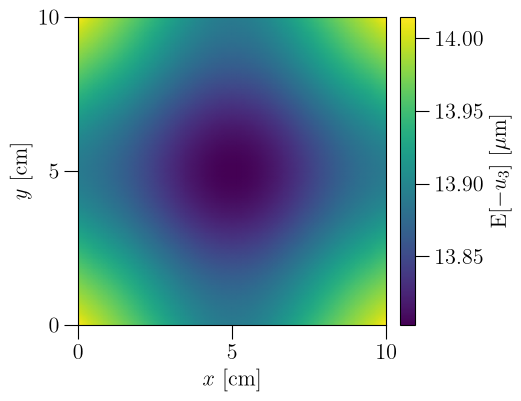

In [10]:
def plot_mean_compression(ax: Axes) -> None:
    data = results_mps[-1]["observables"]["top_compression"]
    x, y = (100 * coordinates for coordinates in data["coordinates"])
    image = ax.pcolormesh(
        x, y, -1e6 * data["mean"].T, shading="gouraud", cmap="viridis", rasterized=True
    )
    ax.set_aspect("equal")
    ax.set_xticks([0, 5, 10])
    ax.set_yticks([0, 5, 10])
    ax.set_xlabel(r"$x$ [cm]")
    ax.set_ylabel(r"$y$ [cm]")
    ax.figure.colorbar(
        image,
        ax=ax,
        fraction=0.043,
        pad=0.03,
        label=r"$\mathrm{E}[-u_3]$ [$\mu$m]",
    )


fig, axs = create_subplots()
plot_mean_compression(axs[0, 0])
fig.savefig("figures/4_compression_mean.pdf", dpi=300, bbox_inches="tight")

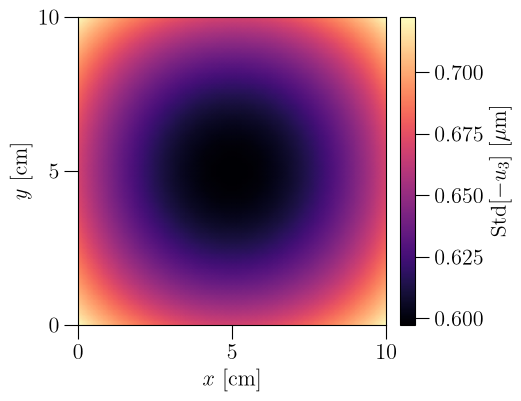

In [11]:
def plot_std_compression(ax: Axes) -> None:
    data = results_mps[-1]["observables"]["top_compression"]
    x, y = (100 * coordinates for coordinates in data["coordinates"])
    image = ax.pcolormesh(
        x, y, 1e6 * data["std"].T, shading="gouraud", cmap="magma", rasterized=True
    )
    ax.set_aspect("equal")
    ax.set_xticks([0, 5, 10])
    ax.set_yticks([0, 5, 10])
    ax.set_xlabel(r"$x$ [cm]")
    ax.set_ylabel(r"$y$ [cm]")
    ax.figure.colorbar(
        image,
        ax=ax,
        fraction=0.043,
        pad=0.03,
        label=r"$\mathrm{Std}[-u_3]$ [$\mu$m]",
    )


fig, axs = create_subplots()
plot_std_compression(axs[0, 0])
fig.savefig("figures/4_compression_std.pdf", dpi=300, bbox_inches="tight")

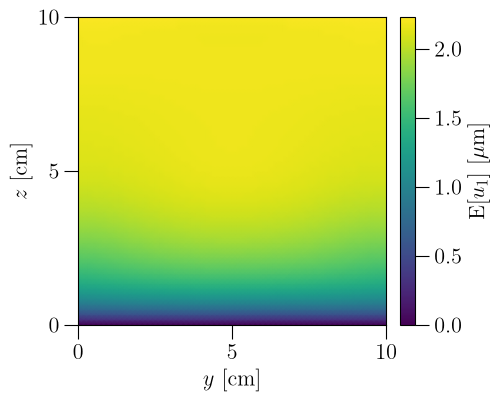

In [12]:
def plot_mean_bulging(ax: Axes) -> None:
    data = results_mps[-1]["observables"]["side_bulge"]
    y, z = (100 * coordinates for coordinates in data["coordinates"])
    image = ax.pcolormesh(
        y, z, 1e6 * data["mean"].T, shading="gouraud", cmap="viridis", rasterized=True
    )
    ax.set_aspect("equal")
    ax.set_xticks([0, 5, 10])
    ax.set_yticks([0, 5, 10])
    ax.set_xlabel(r"$y$ [cm]")
    ax.set_ylabel(r"$z$ [cm]")
    ax.figure.colorbar(
        image,
        ax=ax,
        fraction=0.043,
        pad=0.03,
        label=r"$\mathrm{E}[u_1]$ [$\mu$m]",
    )


fig, axs = create_subplots()
plot_mean_bulging(axs[0, 0])
fig.savefig("figures/4_bulge_mean.pdf", dpi=300, bbox_inches="tight")

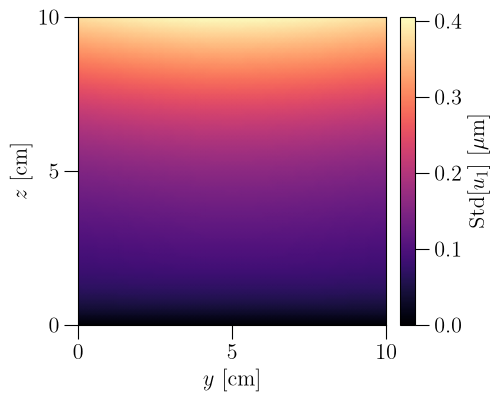

In [13]:
def plot_std_bulging(ax: Axes) -> None:
    data = results_mps[-1]["observables"]["side_bulge"]
    y, z = (100 * coordinates for coordinates in data["coordinates"])
    image = ax.pcolormesh(
        y, z, 1e6 * data["std"].T, shading="gouraud", cmap="magma", rasterized=True
    )
    ax.set_aspect("equal")
    ax.set_xticks([0, 5, 10])
    ax.set_yticks([0, 5, 10])
    ax.set_xlabel(r"$y$ [cm]")
    ax.set_ylabel(r"$z$ [cm]")
    ax.figure.colorbar(
        image,
        ax=ax,
        fraction=0.043,
        pad=0.03,
        label=r"$\mathrm{Std}[u_1]$ [$\mu$m]",
    )


fig, axs = create_subplots()
plot_std_bulging(axs[0, 0])
fig.savefig("figures/4_bulge_std.pdf", dpi=300, bbox_inches="tight")

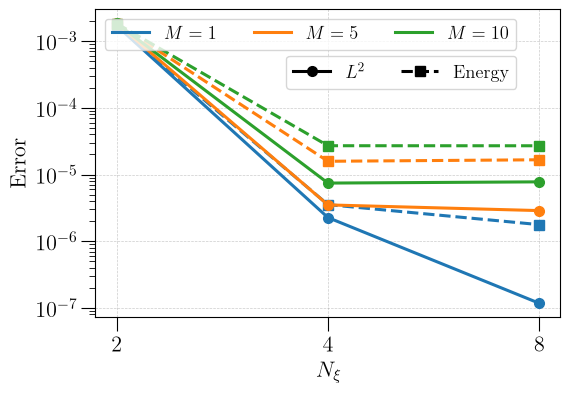

In [14]:
def plot_field_error(ax: Axes) -> None:
    M_plot = [1, 5, 10]
    for i, M in enumerate(M_plot):
        data = [r for r in results_mps if r["M"] == M]
        orders = [r["N_xi"] for r in data]
        ax.plot(orders, [r["audit"]["relative_L2"] for r in data], "-o", color=f"C{i}")
        ax.plot(orders, [r["audit"]["relative_energy"] for r in data], "--s", color=f"C{i}")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")

    handles_M = [Line2D([0], [0], color=f"C{i}", label=rf"$M={M}$") for i, M in enumerate(M_plot)]
    handles_error = [
        Line2D([0], [0], color="black", marker="o", linestyle="-", label=r"$L^2$"),
        Line2D([0], [0], color="black", marker="s", linestyle="--", label="Energy"),
    ]

    ax.add_artist(ax.legend(handles=handles_M, loc="upper left", fontsize="small", ncol=3))
    ax.legend(
        handles=handles_error,
        loc="upper left",
        fontsize="small",
        ncol=2,
        bbox_to_anchor=(0.39, 0.88),
    )

    ax.set_xticks(N_ξ_range, labels=N_ξ_range)
    ax.set_xlabel(r"$N_\xi$")
    ax.set_ylabel("Error")
    ax.grid(True)


fig, axs = create_subplots()
plot_field_error(axs[0, 0])
fig.savefig("figures/4_field_error.pdf", dpi=300, bbox_inches="tight")

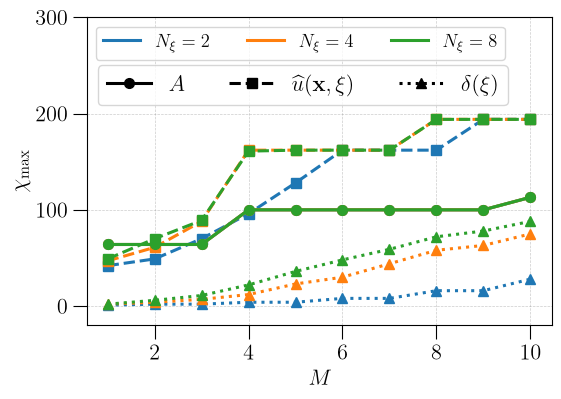

In [15]:
def plot_bond_dimensions(ax: Axes) -> None:
    tensors = (
        ("bond_dimensions_A", r"$A$", "-o"),
        ("bond_dimensions_u", r"$\widehat{u}(\mathbf{x},\xi)$", "--s"),
        ("bond_dimensions_response", r"$\delta(\xi)$", ":^"),
    )

    for i, N_ξ in enumerate(N_ξ_range):
        data = [r for r in results_mps if r["N_xi"] == N_ξ]
        for key, _, style in tensors:
            ax.plot([r["M"] for r in data], [max(r[key]) for r in data], style, color=f"C{i}")

    order_handles = [
        Line2D([0], [0], color=f"C{i}", label=rf"$N_\xi={N_ξ}$") for i, N_ξ in enumerate(N_ξ_range)
    ]
    tensor_handles = [
        Line2D([0], [0], color="black", linestyle=style[:-1], marker=style[-1], label=label)
        for _, label, style in tensors
    ]
    ax.set_ylim(-20, 300)
    ax.add_artist(ax.legend(handles=order_handles, loc="upper left", fontsize="small", ncol=3))
    ax.legend(
        handles=tensor_handles,
        loc="upper left",
        bbox_to_anchor=(0.0, 0.88),
        ncol=3,
    )

    ax.set_xlabel(r"$M$")
    ax.set_ylabel(r"$\chi_{\max}$")
    ax.grid(True)


fig, axs = create_subplots()
plot_bond_dimensions(axs[0, 0])
fig.savefig("figures/4_bond_dimensions.pdf", dpi=300, bbox_inches="tight")

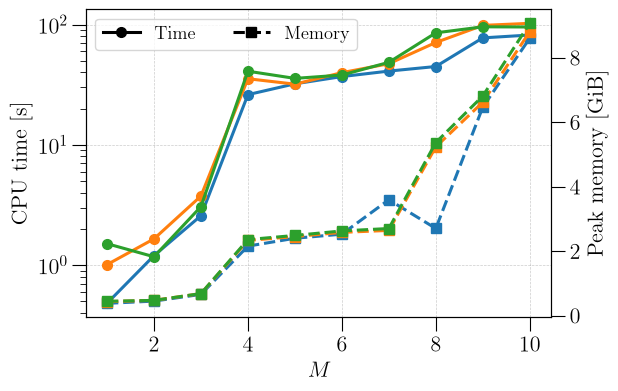

In [16]:
def plot_time_memory(ax: Axes) -> None:
    memory_axis = ax.twinx()
    for i, N_ξ in enumerate(N_ξ_range):
        data = [r for r in results_mps if r["N_xi"] == N_ξ]
        ax.plot([r["M"] for r in data], [r["time_construction"] for r in data], "-o", color=f"C{i}")
        memory_axis.plot(
            [r["M"] for r in data], [r["peak_memory_gib"] for r in data], "--s", color=f"C{i}"
        )
    ax.set_yscale("log")

    handles = [
        Line2D([0], [0], color="black", linestyle="-", marker="o", label="Time"),
        Line2D([0], [0], color="black", linestyle="--", marker="s", label="Memory"),
    ]
    ax.legend(handles=handles, loc="upper left", ncol=2, fontsize="small")

    ax.set_xlabel(r"$M$")
    ax.set_ylabel("CPU time [s]")
    memory_axis.set_ylabel("Peak memory [GiB]")
    ax.grid(True)


fig, axs = create_subplots()
plot_time_memory(axs[0, 0])
fig.savefig("figures/4_time_memory.pdf", dpi=300, bbox_inches="tight")